# Data Processing and Modeling for Fraud Detection

Libreta de procesamiento y modelado de datos para la detección de fraude. Aquí se realizarán las transformaciones necesarias en los datos y se entrenarán modelos para identificar transacciones fraudulentas.

## Librerias necesarias

In [33]:
import pandas as pd
import numpy as np
import os
import time
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

## Cargar los datos preprocesados de México con solo columnas numéricas y la columna is_fraud

In [34]:
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PREPROCESSED_DIR = DATA_DIR / "preprocessed"
mexico_fraud_num = pd.read_csv(PREPROCESSED_DIR / "mexico_fraud_num.csv")
mexico_fraud_num.head()

,transaction_amount,transaction_hour,card_present,customer_age,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,...,amount_vs_avg_ratio,used_chip,used_pin,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,is_fraud,fraud_amount_lost
0,827.60,8,1,26,188,15400.0,769,1,2,2,...,9.194,0,0,0,90.02,65.89,0,0,0,0.0
1,62.19,9,1,52,2129,14520.0,734,4,1,1,...,0.616,1,0,0,100.98,46.77,0,0,0,0.0
2,71.10,10,0,52,143,4730.0,561,2,1,5,...,0.895,0,0,0,79.40,58.88,0,0,0,0.0
3,13.63,11,0,46,387,4300.0,593,2,0,0,...,0.418,0,0,0,32.58,13.23,2,0,0,0.0
4,103.65,11,0,31,379,10650.0,671,2,0,3,...,0.899,0,0,0,115.25,83.16,0,0,0,0.0


In [35]:
#quitamos la columna fraud_amount_lost por que delata directamente el fraude y no aporta información útil para el modelo
mexico_fraud_num = mexico_fraud_num.drop(columns=["fraud_amount_lost"])


In [36]:
mexico_fraud_num.info()

<class 'pandas.DataFrame'>
RangeIndex: 1921 entries, 0 to 1920
Data columns (total 27 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   transaction_amount           1921 non-null   float64
 1   transaction_hour             1921 non-null   int64  
 2   card_present                 1921 non-null   int64  
 3   customer_age                 1921 non-null   int64  
 4   account_age_days             1921 non-null   int64  
 5   credit_limit                 1921 non-null   float64
 6   credit_score                 1921 non-null   int64  
 7   num_cards_held               1921 non-null   int64  
 8   transactions_last_1h         1921 non-null   int64  
 9   transactions_last_24h        1921 non-null   int64  
 10  transactions_last_7d         1921 non-null   int64  
 11  amount_last_1h               1921 non-null   float64
 12  amount_last_24h              1921 non-null   float64
 13  days_since_last_transaction  

## 3. Separar un 20 % de los datos (renglones) del conjunto para las pruebas finales. Le llamaremos a este conjunto X test y al 80 % restante X train.

In [37]:
## Separar características y etiqueta
X = mexico_fraud_num.drop("is_fraud", axis=1)
y = mexico_fraud_num["is_fraud"]

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    mexico_fraud_num.drop(columns=["is_fraud"]), 
    mexico_fraud_num["is_fraud"], 
    test_size=0.2, 
    random_state=42
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1536, 26), (385, 26), (1536,), (385,))

## 4. Aplicar a X train el procedimiento de PCA a las columnas numéricas 
- considerar las 10 primeras componentes— y considerar esta nueva codificación junto con la columna
is fraud.

In [58]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

print(X_train_scaled.shape)

(1536, 26)


In [59]:
pca = PCA(n_components=10)
X_train_pca = pca.fit_transform(X_train_scaled)
print(X_train_pca.shape)

(1536, 10)


In [60]:
# Nueva codificación de X_train (10 componentes) junto con la etiqueta is_fraud
train_pca = pd.DataFrame(X_train_pca, columns=pc_cols, index=X_train.index)
train_pca["is_fraud"] = y_train
train_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,is_fraud
426,-0.935034,-0.833940,-0.498499,1.002924,-1.477103,1.101725,0.375287,1.446361,-0.825853,-0.439224,0
141,0.308608,-2.071289,1.054005,1.789624,4.975764,-1.052805,-1.337412,0.028955,0.138923,1.246933,0
1157,-1.047522,-0.289483,0.088668,0.502425,-1.065909,1.792025,-0.260425,0.358825,-1.007781,0.050776,0
965,0.695091,-0.289025,-1.552763,-1.292944,0.314069,-1.240280,1.153005,1.380509,0.701538,1.807115,0
1829,-0.090587,-0.977846,-0.297848,-1.716252,0.401468,-0.755966,-1.772982,-0.500341,0.445513,1.293699,0


In [61]:
# Comprobación numérica de la relación entre PCA y la SVD de X_train_scaled = U Σ Vᵀ
# (X_train_scaled ya está centrada por el StandardScaler, así que no hay que restar la media)
U, S, Vt = np.linalg.svd(X_train_scaled, full_matrices=False)
n = X_train_scaled.shape[0]

# Los signos de los vectores singulares son arbitrarios, por eso se comparan valores absolutos
print("components_ == primeras 10 filas de Vᵀ:", np.allclose(np.abs(pca.components_), np.abs(Vt[:10])))
print("X_train_pca == U₁₀ Σ₁₀:              ", np.allclose(np.abs(X_train_pca), np.abs(U[:, :10] * S[:10])))
print("varianzas == σᵢ² / (n − 1):           ", np.allclose(pca.explained_variance_, S[:10] ** 2 / (n - 1)))

components_ == primeras 10 filas de Vᵀ: True
X_train_pca == U₁₀ Σ₁₀:               True
varianzas == σᵢ² / (n − 1):            True


## 5. Preparar el conjunto de prueba: X_test_pca

A `X_test` se le aplican `scaler.transform` y después `pca.transform`. No se hace de cero la reducción de dimensionalidad: se reutilizan el escalado y las 10 componentes **aprendidas en X_train**.

In [62]:
# Aplicar scaler a X_test
X_test_scaled = scaler.transform(X_test)

# Aplicar PCA a X_test_scaled
X_test_pca = pca.transform(X_test_scaled)
print(X_test_pca.shape)

(385, 10)


# Propuestas:

## 1. Distancia de Mahalanobis

Se toman las transacciones legítimas de `X_train_pca` (`X_train_legit`) y su matriz de covarianzas Σ. La distancia de Mahalanobis al origen es

$$d_M(x)^2 = x^T \Sigma^{-1} x$$

Para cada porcentaje entero n % se busca un radio ρₙ tal que la bola $B_{\rho_n}(0) = \{x : d_M(x) \le \rho_n\}$ contenga el n % de las transacciones legítimas, pero no el (n+1) %.

In [63]:
def distancia_mahalanobis(X, sigma_inv):
    """d_M(x) = √(xᵀ Σ⁻¹ x) para cada renglón x de X (distancia al origen)."""
    return np.sqrt(np.sum((X @ sigma_inv) * X, axis=1))


def radio(distancias, n):
    """Radio ρₙ tal que la bola B_ρₙ(0) contiene el n % de los datos, pero no el (n+1) %.

    Se ordenan las distancias y se toma la k-ésima más pequeña, con k = ⌈n·N/100⌉
    (el mínimo número de puntos que cubre el n %).
    """
    assert 1 <= n <= 100, "n debe ser un porcentaje entero entre 1 y 100"
    d = np.sort(distancias)
    k = int(np.ceil(n * len(d) / 100))
    return d[k - 1]

In [66]:
# Obtener transacciones legítimas y fraudes en el conjunto de prueabs
transacciones_legitimas = (y_train == 0).to_numpy()
X_train_legitimas = X_train_pca[transacciones_legitimas]   
X_train_fraudes = X_train_pca[~transacciones_legitimas]

print("X_train_legit: ", X_train_legitimas.shape)
print("X_train_fraude:", X_train_fraudes.shape)

X_train_legit:  (1492, 10)
X_train_fraude: (44, 10)


In [67]:
PORCENTAJES = [50, 75, 90, 95, 99]   # % de transacciones legítimas dentro de cada bola
CORTES_FRAUDE = [10, 25, 50]         # % de fraudes de entrenamiento que definen las zonas (decisión de diseño)
ZONAS = ["Seguridad extrema", "Seguridad alta", "Seguridad baja", "Peligro"]


def mahalanobis(k):
    """Ajusta el método con las primeras k componentes y calcula las distancias de X_test_pca."""
    inicio = time.perf_counter()

    legit, fraude, test = X_train_legit[:, :k], X_train_fraude[:, :k], X_test_pca[:, :k]
    sigma = np.cov(legit, rowvar=False)  # Σ de las transacciones legítimas (k × k)
    sigma_inv = np.linalg.inv(sigma)
    d_legit = distancia_mahalanobis(legit, sigma_inv)
    d_fraude = distancia_mahalanobis(fraude, sigma_inv)

    modelo = {
        "k": k,
        "sigma": sigma,
        "d_legit": d_legit,
        "d_fraude": d_fraude,
        "radios": {n: radio(d_legit, n) for n in PORCENTAJES},
        "radios_zona": [radio(d_fraude, c) for c in CORTES_FRAUDE],
        "d_test": distancia_mahalanobis(test, sigma_inv),
    }
    modelo["tiempo_s"] = time.perf_counter() - inicio
    return modelo

In [68]:
def tabla_radios(modelo):
    """% de legítimas y de fraudes de entrenamiento dentro de cada bola B_ρₙ(0)."""
    radios = modelo["radios"]
    return pd.DataFrame(
        {
            "ρ": radios.values(),
            "% legítimas dentro": [100 * np.mean(modelo["d_legit"] <= r) for r in radios.values()],
            "% fraudes dentro": [100 * np.mean(modelo["d_fraude"] <= r) for r in radios.values()],
        },
        index=[f"ρ{n}" for n in radios],
    ).round(2)


def tabla_zonas(modelo):
    """Transacciones legítimas y fraudulentas de X_test_pca en cada zona de seguridad."""
    zona = np.searchsorted(modelo["radios_zona"], modelo["d_test"])  # 0 = extrema, …, 3 = peligro
    y_real = y_test.to_numpy()
    tabla = pd.DataFrame(
        {
            "radio exterior": [*modelo["radios_zona"], np.inf],
            "legítimas": [np.sum((zona == i) & (y_real == 0)) for i in range(len(ZONAS))],
            "fraudes": [np.sum((zona == i) & (y_real == 1)) for i in range(len(ZONAS))],
        },
        index=ZONAS,
    )
    tabla["% fraude en la zona"] = 100 * tabla["fraudes"] / (tabla["legítimas"] + tabla["fraudes"])
    return tabla.round(2)


def tabla_confusion(modelo):
    """Matriz de confusión en un renglón para cada umbral (fraude si d > ρ), evaluada en X_test_pca."""
    umbrales = {f"ρ{n}": r for n, r in modelo["radios"].items()}
    umbrales["inicio zona Peligro"] = modelo["radios_zona"][-1]
    filas = []
    for nombre, r in umbrales.items():
        prediccion = (modelo["d_test"] > r).astype(int)
        vn, fp, fn, vp = confusion_matrix(y_test, prediccion, labels=[0, 1]).ravel()
        filas.append({"umbral": nombre, "ρ": r, "VN": vn, "FP": fp, "FN": fn, "VP": vp})
    return pd.DataFrame(filas).set_index("umbral").round(2)

## 1.1 ejercicio con dos bolas

In [69]:
m2 = mahalanobis(2)

# Comprobación del programa para todos los porcentajes enteros: B_ρₙ(0) contiene el n %, pero no el (n+1) %
pct_dentro = {n: 100 * np.mean(m2["d_legit"] <= radio(m2["d_legit"], n)) for n in range(1, 100)}
assert all(n <= p < n + 1 for n, p in pct_dentro.items())
print("✓ Para n = 1, …, 99 la bola B_ρₙ(0) contiene el n % de las legítimas, pero no el (n+1) %")

tabla_radios(m2)

✓ Para n = 1, …, 99 la bola B_ρₙ(0) contiene el n % de las legítimas, pero no el (n+1) %


,ρ,% legítimas dentro,% fraudes dentro
ρ50,1.07,50.00,38.64
ρ75,1.38,75.00,75.00
ρ90,1.91,90.01,93.18
ρ95,2.36,95.04,100.00
ρ99,4.06,99.06,100.00


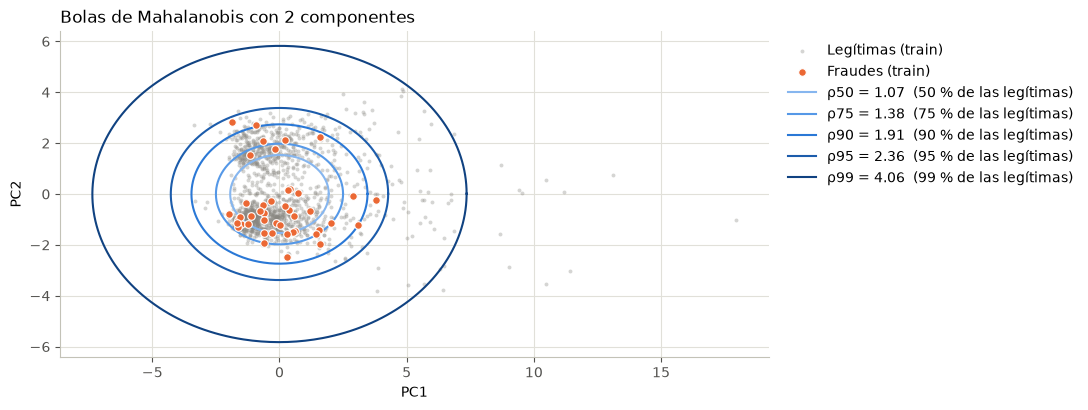

In [70]:
def elipse(radio, sigma, puntos=400):
    """Frontera de la bola {x ∈ R² : xᵀ Σ⁻¹ x = ρ²}.

    Si Σ = L Lᵀ (Cholesky) y u recorre el círculo unitario, entonces x = ρ L u cumple xᵀ Σ⁻¹ x = ρ².
    """
    L = np.linalg.cholesky(sigma)
    t = np.linspace(0, 2 * np.pi, puntos)
    circulo = np.vstack([np.cos(t), np.sin(t)])
    return (radio * L @ circulo).T


COLOR_LEGIT = "#898781"   # gris: contexto
COLOR_FRAUDE = "#eb6834"  # naranja: fraudes
COLORES_RADIOS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]  # azul, de claro (ρ50) a oscuro (ρ99)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(*X_train_legit[:, :2].T, s=8, color=COLOR_LEGIT, alpha=0.35, linewidths=0, label="Legítimas (train)")
ax.scatter(*X_train_fraude[:, :2].T, s=30, color=COLOR_FRAUDE, edgecolors="white", linewidths=0.8,
           zorder=3, label="Fraudes (train)")
for (n, r), color in zip(m2["radios"].items(), COLORES_RADIOS):
    ex, ey = elipse(r, m2["sigma"]).T
    ax.plot(ex, ey, color=color, linewidth=1.5, label=f"ρ{n} = {r:.2f}  ({n} % de las legítimas)")

ax.set_title("Bolas de Mahalanobis con 2 componentes", loc="left")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_aspect("equal", adjustable="box")  # misma escala en ambos ejes: las elipses se ven con su forma real
ax.grid(color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

In [71]:
# Zonas de seguridad y validación en X_test_pca (2 componentes)
display(tabla_zonas(m2))
tabla_confusion(m2)

,radio exterior,legítimas,fraudes,% fraude en la zona
Seguridad extrema,0.41,25,0,0.00
Seguridad alta,0.76,75,2,2.60
Seguridad baja,1.11,109,2,1.80
Peligro,inf,168,4,2.33


,ρ,VN,FP,FN,VP
umbral,,,,,
ρ50,1.07,199,178,4,4
ρ75,1.38,269,108,6,2
ρ90,1.91,349,28,8,0
ρ95,2.36,363,14,8,0
ρ99,4.06,375,2,8,0
inicio zona Peligro,1.11,209,168,4,4


## 1.2 ejercicio con más bolas

In [72]:
m10 = mahalanobis(10)
tabla_radios(m10)

,ρ,% legítimas dentro,% fraudes dentro
ρ50,2.72,50.00,43.18
ρ75,3.38,75.00,70.45
ρ90,4.18,90.01,95.45
ρ95,4.79,95.04,97.73
ρ99,7.06,99.06,100.00


In [73]:
# Zonas de seguridad y validación en X_test_pca (10 componentes)
display(tabla_zonas(m10))
tabla_confusion(m10)

,radio exterior,legítimas,fraudes,% fraude en la zona
Seguridad extrema,1.91,28,0,0.00
Seguridad alta,2.35,63,2,3.08
Seguridad baja,2.94,133,4,2.92
Peligro,inf,153,2,1.29


,ρ,VN,FP,FN,VP
umbral,,,,,
ρ50,2.72,178,199,4,4
ρ75,3.38,288,89,6,2
ρ90,4.18,340,37,6,2
ρ95,4.79,358,19,7,1
ρ99,7.06,373,4,8,0
inicio zona Peligro,2.94,224,153,6,2


### 1.2.1 Comparación: 2 vs 10 componentes

In [74]:
# Resumen para el reporte: varianza explicada, tiempo de ejecución y matriz de confusión en un renglón
resumen = []
for modelo in [m2, m10]:
    confusion = tabla_confusion(modelo)
    for umbral in ["ρ95", "inicio zona Peligro"]:
        vn, fp, fn, vp = (int(confusion.loc[umbral, c]) for c in ["VN", "FP", "FN", "VP"])
        resumen.append({
            "componentes": modelo["k"],
            "umbral": umbral,
            "varianza explicada": pca.explained_variance_ratio_[: modelo["k"]].sum(),
            "tiempo (ms)": 1000 * modelo["tiempo_s"],
            "VN": vn, "FP": fp, "FN": fn, "VP": vp,
            "% fraudes detectados": 100 * vp / (vp + fn),
            "% falsas alarmas": 100 * fp / (fp + vn),
        })

pd.DataFrame(resumen).set_index(["componentes", "umbral"]).round(3)

varianza explicada  tiempo (ms)   VN   FP  \
componentes umbral                                                           
2           ρ95                               0.220        2.109  363   14   
            inicio zona Peligro               0.220        2.109  209  168   
10          ρ95                               0.667        0.908  358   19   
            inicio zona Peligro               0.667        0.908  224  153   

                                 FN  VP  % fraudes detectados  \
componentes umbral                                              
2           ρ95                   8   0                   0.0   
            inicio zona Peligro   4   4                  50.0   
10          ρ95                   7   1                  12.5   
            inicio zona Peligro   6   2                  25.0   

                                 % falsas alarmas  
componentes umbral                                 
2           ρ95                             3.714  
            inicio zona Peligro            44.562  
10          ρ95                             5.040  
            inicio zona Peligro            40.584